# **0. GVC Assessment: Problem description**

The aim is to predict the house prices from a specific dataset using a regression analysis.

1. **Data management**, i.e. you have to:
  * Manage the N/A in some fields
  * You have some variables starting with a number (1stFlrSF and 2ndFlrSF)
  * GarageYrBlt has invalid year entry, i.e. 2207, which needs to be 2007
  * Exterior1st and Exterior2nd have entries which are having spaces between the two words, i.e. Wd Sdng, Brk Cmn, that needs to be handled. As well as amongst the Exterior2nd variable there is an entry containing a typo, i.e. instead of WdShing as another similar entry, it's written Wd Shng.
 
2. **Descriptive statistics** (explore your data and the variables relationships you think are important to look at)
 
3. **Regression analysis**, i.e. which are the factors that influence the sale price of a house? You’ll need to define those and then interpret the results. (NB: As mentioned, you could choose to test in your model just few of all variables in the dataset, but if you choose to do so, please justify your choice.)

**Note**: It's assumed that the house prices are in constant prices not in current prices.


In [ ]:
import warnings
warnings.filterwarnings("ignore")

from xgboost import XGBRegressor
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib.colors import ListedColormap
import matplotlib.pyplot as plt
import statsmodels.api as sm 
import pylab as py 
from sklearn import linear_model
import os
import pickle

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score, train_test_split 
from sklearn.metrics import mean_squared_error as MSE
from sklearn import preprocessing, metrics
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

#from google.colab import drive
# mount google drive information in a google colaboratory directory
#drive.mount('/content/gdrive')

First of all, we read the excel file, one sheet contains information about the sale price and the other contain information about the characteristic of each valued house.

# **1. Data Management**
## **1.0 Read Files**

In [ ]:
#path = r'gdrive/My Drive/GVC/Data/' # path
path = 'Data/' # path
y = pd.read_excel(path+'Dataset_regression analysis.xlsx', 
                   index_col='Id',
                   sheet_name='SalePrice (Y var)')

X = pd.read_excel(path+'Dataset_regression analysis.xlsx', 
                   index_col='Id',
                   sheet_name='Dataset house caracteristics')

In [ ]:
X.head()

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
Id,,,,,,,,,,,,,,,,,,,,,
1461,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,Inside,...,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
1462,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,Corner,...,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
1463,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal
1464,60,RL,78.0,9978,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,0,NaN,NaN,NaN,0,6,2010,WD,Normal
1465,120,RL,43.0,5005,Pave,NaN,IR1,HLS,AllPub,Inside,...,144,0,NaN,NaN,NaN,0,1,2010,WD,Normal


The dataset contains 1459 houses and 79 variables

In [ ]:
X.shape

(1459, 79)

## **1.1.Categorical's variables treatment**

### **1.1.1 Summary measures** 

In [ ]:
descriptive_table = X.describe(include='all').round(decimals=3)
description_object=descriptive_table.loc[['count','unique','top','freq']] 
description_object.dropna(axis=1, thresh=None, inplace=True)
description_object

,MSZoning,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,...,GarageType,GarageFinish,GarageQual,GarageCond,PavedDrive,PoolQC,Fence,MiscFeature,SaleType,SaleCondition
count,1455,1459,107,1459,1459,1457,1459,1459,1459,1459,...,1383,1381,1381,1381,1459,3,290,51,1458,1459
unique,5,2,2,4,4,1,5,3,25,9,...,6,3,4,5,3,2,4,3,9,6
top,RL,Pave,Grvl,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Norm,...,Attchd,Unf,TA,TA,Y,Ex,MnPrv,Shed,WD,Normal
freq,1114,1453,70,934,1311,1457,1081,1396,218,1251,...,853,625,1293,1328,1301,2,172,46,1258,1204


### **1.1.2 Delete columns**:
- With only one value (1 categories with few NaN, ie. *utilities*) because this make the model overfitting and this should be avoided.
- With a vast majority of houses with only one value shold be deleting (*Street*, *Condition2*, *RoofMatl*, *Heating*)
- With a vast majority of NaNs should be deleted (ie. *Pool QC*)

In [ ]:
X.drop(columns=['Utilities','Street','Condition2','RoofMatl','Heating','PoolQC'],inplace=True)

### **1.1.3 Replace Missing values**:


In [ ]:
X.Alley.fillna('No',inplace=True) # NA 	No alley access
pd.value_counts(X.Alley)

No      1352
Grvl      70
Pave      37
Name: Alley, dtype: int64

In [ ]:
#MSZoning: Identifies the general zoning classification of the sale.
X.MSZoning.fillna('Other',inplace=True) 
pd.value_counts(X.MSZoning)

RL         1114
RM          242
FV           74
C (all)      15
RH           10
Other         4
Name: MSZoning, dtype: int64

In [ ]:
X.Exterior1st.fillna('Other',inplace=True) 
pd.value_counts(X.Exterior1st)

VinylSd    510
MetalSd    230
HdBoard    220
Wd Sdng    205
Plywood    113
CemntBd     65
BrkFace     37
WdShing     30
AsbShng     24
Stucco      18
BrkComm      4
Other        1
AsphShn      1
CBlock       1
Name: Exterior1st, dtype: int64

In [ ]:
X.Exterior2nd.fillna('Other',inplace=True) 
pd.value_counts(X.Exterior2nd)

VinylSd    510
MetalSd    233
HdBoard    199
Wd Sdng    194
Plywood    128
CmentBd     66
Wd Shng     43
BrkFace     22
Stucco      21
AsbShng     18
Brk Cmn     15
ImStucc      5
CBlock       2
Stone        1
Other        1
AsphShn      1
Name: Exterior2nd, dtype: int64

In [ ]:
X.MasVnrType.fillna('None',inplace=True) 
pd.value_counts(X.MasVnrType)

None       894
BrkFace    434
Stone      121
BrkCmn      10
Name: MasVnrType, dtype: int64

In [ ]:
X.BsmtQual.fillna('No',inplace=True) #No Basement
pd.value_counts(X.BsmtQual)

TA    634
Gd    591
Ex    137
Fa     53
No     44
Name: BsmtQual, dtype: int64

In [ ]:
X.BsmtCond.fillna('No',inplace=True) #NA	No Basement
pd.value_counts(X.BsmtCond)

TA    1295
Fa      59
Gd      57
No      45
Po       3
Name: BsmtCond, dtype: int64

In [ ]:
X.BsmtExposure.fillna('Nb',inplace=True) #No Basement
pd.value_counts(X.BsmtExposure)

No    951
Av    197
Gd    142
Mn    125
Nb     44
Name: BsmtExposure, dtype: int64

In [ ]:
X.BsmtFinType1.fillna('Nb',inplace=True) #No Basement
pd.value_counts(X.BsmtFinType1)

GLQ    431
Unf    421
ALQ    209
Rec    155
BLQ    121
LwQ     80
Nb      42
Name: BsmtFinType1, dtype: int64

In [ ]:
X.BsmtFinType2.fillna('Nb',inplace=True) #No Basement
pd.value_counts(X.BsmtFinType2)

Unf    1237
Rec      51
Nb       42
LwQ      41
BLQ      35
ALQ      33
GLQ      20
Name: BsmtFinType2, dtype: int64

In [ ]:
#there is one house without kitchen quality data
X[X.KitchenQual.isna()].KitchenAbvGr

Id
1556    1
Name: KitchenAbvGr, dtype: int64

In [ ]:
X.KitchenQual.fillna('TA',inplace=True) #average value
pd.value_counts(X.KitchenQual)

TA    758
Gd    565
Ex    105
Fa     31
Name: KitchenQual, dtype: int64

In [ ]:
#Functional: Home functionality (Assume typical unless deductions are warranted)
X.Functional.fillna('Typ',inplace=True) #average value
pd.value_counts(X.Functional)

Typ     1359
Min2      36
Min1      34
Mod       20
Maj1       5
Maj2       4
Sev        1
Name: Functional, dtype: int64

In [ ]:
X.FireplaceQu.fillna('No',inplace=True) #average value
pd.value_counts(X.FireplaceQu)

No    730
Gd    364
TA    279
Fa     41
Po     26
Ex     19
Name: FireplaceQu, dtype: int64

In [ ]:
X.GarageType.fillna('No',inplace=True) #average value
pd.value_counts(X.GarageType)

Attchd     853
Detchd     392
BuiltIn     98
No          76
Basment     17
2Types      17
CarPort      6
Name: GarageType, dtype: int64

In [ ]:
X.GarageFinish.fillna('No',inplace=True) #average value
pd.value_counts(X.GarageFinish)

Unf    625
RFn    389
Fin    367
No      78
Name: GarageFinish, dtype: int64

In [ ]:
X.GarageQual.fillna('No',inplace=True) #average value
pd.value_counts(X.GarageQual)

TA    1293
No      78
Fa      76
Gd      10
Po       2
Name: GarageQual, dtype: int64

In [ ]:
X.GarageCond.fillna('No',inplace=True) #average value
pd.value_counts(X.GarageCond).sort_index()

Ex       1
Fa      39
Gd       6
No      78
Po       7
TA    1328
Name: GarageCond, dtype: int64

In [ ]:
X.Fence.fillna('No',inplace=True) #average value
pd.value_counts(X.Fence)

No       1169
MnPrv     172
GdPrv      59
GdWo       58
MnWw        1
Name: Fence, dtype: int64

In [ ]:
# it only describe if it have a Shed (over 100 SF) or not
X.MiscFeature.fillna('No',inplace=True) #average value
pd.value_counts(X.MiscFeature)

No      1408
Shed      46
Gar2       3
Othr       2
Name: MiscFeature, dtype: int64

In [ ]:
X.SaleType.fillna('Oth',inplace=True) #average value
pd.value_counts(X.SaleType)

WD       1258
New       117
COD        44
ConLD      17
CWD         8
Oth         5
ConLI       4
ConLw       3
Con         3
Name: SaleType, dtype: int64

### **1.1.4 Transform** some categorical variables into ordinals by scoring them


In [ ]:
scoring={'No':0, 'Po':1, 'Fa':2, 'TA':3, 'Gd':4, 'Ex':5}

X.GarageCond= X.GarageCond.map(scoring)
X.GarageQual= X.GarageQual.map(scoring)
X.FireplaceQu= X.FireplaceQu.map(scoring)
X.KitchenQual= X.KitchenQual.map(scoring)
X.BsmtCond= X.BsmtCond.map(scoring)
X.BsmtQual= X.BsmtQual.map(scoring)
X.ExterQual= X.ExterQual.map(scoring)
X.ExterCond= X.ExterCond.map(scoring)
X.HeatingQC= X.HeatingQC.map(scoring)

#LandSlope
Slope={'Sev':1, 'Mod':2, 'Gtl':3}
X.LandSlope = X.LandSlope.map(Slope)

#LotShape
Shape={'IR3':4, 'IR2':3, 'IR1':2, 'Reg':1}
X.LotShape = X.LotShape.map(Shape)

#Functional
Functional={'Sev':1, 'Maj2':2, 'Maj1':2, 'Mod':3, 'Min1':4,'Min2':4,'Typ':5}
X.Functional = X.Functional.map(Functional)

#BsmtExposure: Refers to walkout or garden level walls
Exposure={'Gd':4, 'Av':3, 'Mn':2, 'No':1, 'Nb':0}
X.BsmtExposure = X.BsmtExposure.map(Exposure)



### **1.1.5 Analyse the rest of the categorical variables** 

In order to discover small categories

In [ ]:
pd.value_counts(X.LotConfig)

Inside     1081
Corner      248
CulDSac      82
FR2          38
FR3          10
Name: LotConfig, dtype: int64

In [ ]:
pd.value_counts(X.LandContour)

Lvl    1311
HLS      70
Bnk      54
Low      24
Name: LandContour, dtype: int64

In [ ]:
pd.value_counts(X.Condition1)

Norm      1251
Feedr       83
Artery      44
RRAn        24
PosN        20
RRAe        17
PosA        12
RRNn         4
RRNe         4
Name: Condition1, dtype: int64

In [ ]:
pd.value_counts(X.HouseStyle)

1Story    745
2Story    427
1.5Fin    160
SLvl       63
SFoyer     46
2.5Unf     13
1.5Unf      5
Name: HouseStyle, dtype: int64

In [ ]:
pd.value_counts(X.RoofStyle)

Gable      1169
Hip         265
Gambrel      11
Flat          7
Mansard       4
Shed          3
Name: RoofStyle, dtype: int64

In [ ]:
pd.value_counts(X.Foundation)

PConc     661
CBlock    601
BrkTil    165
Slab       25
Stone       5
Wood        2
Name: Foundation, dtype: int64

In [ ]:
pd.value_counts(X.Electrical)

SBrkr    1337
FuseA      94
FuseF      23
FuseP       5
Name: Electrical, dtype: int64

In [ ]:
pd.value_counts(X.SaleCondition)

Normal     1204
Partial     120
Abnorml      89
Family       26
Alloca       12
AdjLand       8
Name: SaleCondition, dtype: int64

In [ ]:
pd.value_counts(X.Neighborhood)

NAmes      218
OldTown    126
CollgCr    117
Somerst     96
Edwards     94
NridgHt     89
Gilbert     86
Sawyer      77
SawyerW     66
Mitchel     65
NWAmes      58
IDOTRR      56
Crawfor     52
BrkSide     50
Timber      34
NoRidge     30
StoneBr     26
SWISU       23
MeadowV     20
ClearCr     16
NPkVill     14
BrDale      14
Veenker     13
Blmngtn     11
Blueste      8
Name: Neighborhood, dtype: int64

### **1.1.6 Group small categories**: 

Categories with less than 30 cases is considered as Other because is not enough for draw significant conclusions from this category (if it is possible)

In [ ]:
X.MSZoning=np.where(X.MSZoning.isin(['RH','C (all)']),'Other',X.MSZoning)

X.Exterior1st=np.where(X.Exterior1st.isin(['BrkComm','BrkFace']),'Brick',X.Exterior1st)
X.Exterior1st=np.where(X.Exterior1st.isin(['Wd Sdng','WdShing']),'Wood',X.Exterior1st)
X.Exterior1st=np.where(X.Exterior1st.isin(['AsphShn','AsbShng','CBlock','Stucco']),'Other',X.Exterior1st)

X.Exterior2nd=np.where(X.Exterior2nd.isin(['BrkComm','BrkFace','Brk Cmn']),'Brick',X.Exterior2nd)
X.Exterior2nd=np.where(X.Exterior2nd.isin(['Wd Sdng','WdShing','Wd Shng']),'Wood',X.Exterior2nd)
X.Exterior2nd=np.where(X.Exterior2nd.isin(['AsphShn','AsbShng','CBlock','Stucco','Stone','ImStucc']),'Other',X.Exterior2nd)

X.MasVnrType=np.where(X.MasVnrType.isin(['BrkCmn','BrkFace']),'Brick',X.MasVnrType)

X.BsmtFinType2=np.where(X.BsmtFinType2.isin(['GLQ','ALQ','BLQ']),'LQ',X.BsmtFinType2)

X.GarageType=np.where(X.GarageType.isin(['2Types','Basment','CarPort']),'Other',X.GarageType)

X.Fence=np.where(X.Fence=='MnWw','MnPrv',X.Fence)

X.MiscFeature=np.where(X.MiscFeature.isin(['Gar2','Othr']),'No',X.MiscFeature)

X.SaleType=np.where(X.SaleType.isin(['WD','CWD','VWD','Oth']),'Warranty',X.SaleType)
X.SaleType=np.where(X.SaleType.isin(['Con','ConLw','ConLI','ConLD']),'Contract',X.SaleType)

X.LotConfig=np.where(X.LotConfig.isin(['FR3','FR2']),'FR23',X.LotConfig)

X.Condition1=np.where(X.Condition1.isin(['RRNn','RRNe','RRAn','RRAe']),'RRN',X.Condition1)
X.Condition1=np.where(X.Condition1.isin(['PosA','PosN']),'Pos',X.Condition1)

X.HouseStyle=np.where(X.HouseStyle=='1.5Unf','1Story',X.HouseStyle)
X.HouseStyle=np.where(X.HouseStyle=='2.5Unf','2Story',X.HouseStyle)

X.RoofStyle=np.where(X.RoofStyle.isin(['Gambrel','Flat','Mansard','Shed']),'Other',X.RoofStyle)

X.Foundation=np.where(X.Foundation.isin(['Slab','Stone','Wood']),'Other',X.Foundation)

X.Electrical=np.where(X.Electrical.isin(['FuseA','FuseF','FuseP']),'Fuse',X.Electrical)

X.SaleCondition=np.where(X.SaleCondition.isin(['Family','Alloca','AdjLand']),'Other',X.SaleCondition)

X.Neighborhood=np.where(X.Neighborhood.isin(['StoneBr','SWISU','MeadowV','ClearCr',
                                             'NPkVill','BrDale','Veenker','Blmngtn','Blueste']),'Other',X.Neighborhood)


In [ ]:
descriptive_table = X.describe(include='all').round(decimals=3)
description_object=descriptive_table.loc[['count','unique','top','freq']] 
description_object.dropna(axis=1, thresh=None, inplace=True)
description_object

,MSZoning,Alley,LandContour,LotConfig,Neighborhood,Condition1,BldgType,HouseStyle,RoofStyle,Exterior1st,...,BsmtFinType2,CentralAir,Electrical,GarageType,GarageFinish,PavedDrive,Fence,MiscFeature,SaleType,SaleCondition
count,1459,1459,1459,1459,1459,1459,1459,1459,1459,1459,...,1459,1459,1459,1459,1459,1459,1459,1459,1459,1459
unique,4,3,4,4,17,5,5,5,3,8,...,5,2,2,5,4,3,4,2,4,4
top,RL,No,Lvl,Inside,NAmes,Norm,1Fam,1Story,Gable,VinylSd,...,Unf,Y,SBrkr,Attchd,Unf,Y,No,No,Warranty,Normal
freq,1114,1352,1311,1081,218,1251,1205,750,1169,510,...,1237,1358,1337,853,625,1301,1169,1413,1271,1204


## **1.2.Numeric's variables treatment**

### **1.2.1 Summary measures**

In [ ]:
descriptive_table = X.describe(include='all').round(decimals=3)
description_numeric=descriptive_table.loc[['count','mean','std','min','25%','50%','75%','max']]   
description_numeric.dropna(axis=1, thresh=None, inplace=True)
description_numeric

,MSSubClass,LotFrontage,LotArea,LotShape,LandSlope,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,...,GarageCond,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold
count,1459.000,1232.000,1459.000,1459.000,1459.000,1459.000,1459.000,1459.000,1459.000,1444.000,...,1459.000,1459.000,1459.000,1459.000,1459.000,1459.000,1459.000,1459.000,1459.000,1459.000
mean,57.378,68.580,9819.161,1.392,2.955,6.079,5.554,1971.358,1983.663,100.709,...,2.809,93.175,48.314,24.243,1.794,17.064,1.744,58.168,6.104,2007.770
std,42.747,22.377,4955.517,0.558,0.218,1.437,1.114,30.390,21.130,177.626,...,0.705,127.745,68.883,67.228,20.208,56.610,30.492,630.807,2.722,1.302
min,20.000,21.000,1470.000,1.000,1.000,1.000,1.000,1879.000,1950.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,2006.000
25%,20.000,58.000,7391.000,1.000,3.000,5.000,5.000,1953.000,1963.000,0.000,...,3.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,4.000,2007.000
50%,50.000,67.000,9399.000,1.000,3.000,6.000,5.000,1973.000,1992.000,0.000,...,3.000,0.000,28.000,0.000,0.000,0.000,0.000,0.000,6.000,2008.000
75%,70.000,80.000,11517.500,2.000,3.000,7.000,6.000,2001.000,2004.000,164.000,...,3.000,168.000,72.000,0.000,0.000,0.000,0.000,0.000,8.000,2009.000
max,190.000,200.000,56600.000,4.000,3.000,10.000,9.000,2010.000,2010.000,1290.000,...,5.000,1424.000,742.000,1012.000,360.000,576.000,800.000,17000.000,12.000,2010.000


Changes in *Garage year built*, *YearRemodAdd* and *YrSold*:

In [ ]:
# this value needs to be edited
X.GarageYrBlt = np.where(X.GarageYrBlt==2207,2007,X.GarageYrBlt)

# it is noticed that the garage must to be built after the original construction date (YearBuilt). if that is not happening we have to change
# the garage built date to the original construction date
X.GarageYrBlt = np.where(X.GarageYrBlt < X.YearBuilt, X.YearBuilt, X.GarageYrBlt)

In [ ]:
# the same happened (compared with the garage built variable) with the Remodel date:
X.YearRemodAdd = np.where(X.YearRemodAdd < X.YearBuilt, X.YearBuilt, X.YearRemodAdd)

X.YearRemodAdd = np.where(X.YearRemodAdd > X.YrSold, X.YrSold, X.YearRemodAdd)


# the same happened (compared with the garage built variable) with the YrSold:
X.YrSold = np.where(X.YrSold < X.YearBuilt, X.YearBuilt, X.YrSold)

### **1.2.2 Replace NA**

In [ ]:
X.LotFrontage.fillna(0,inplace=True)
X.MasVnrArea.fillna(0,inplace=True)
X.BsmtFullBath.fillna(0,inplace=True)
X.GarageCars.fillna(0,inplace=True)
X.GarageArea.fillna(0,inplace=True)
X.BsmtFinSF1.fillna(0,inplace=True)
X.BsmtUnfSF.fillna(0,inplace=True)
X.BsmtFinSF2.fillna(0,inplace=True)
X.TotalBsmtSF.fillna(0,inplace=True)
X.BsmtHalfBath.fillna(0,inplace=True)

### **1.2.3 Rename variable** which start with numbers:

In [ ]:
X.rename(columns={'1stFlrSF':'FstFlrSF',
                   '2ndFlrSF':'SndFlrSF',
                   '3SsnPorch':'ThrSsnPorch'}, inplace=True)

### **1.2.4 Variables Creations**:

In [ ]:
X.hasgarage=np.where(X.GarageYrBlt.isna(),0,1)

Enclosed porch, Three season porch and Screen porch area in square feet are sumarized because are more or less the same. In fact are Enclosed porch.

In [ ]:
X.EnclosedPorch=X.EnclosedPorch+X.ThrSsnPorch+X.ScreenPorch
X.drop(columns=['ThrSsnPorch','ScreenPorch'],inplace=True)

### **1.2.5 Drop Variables**
- **Pool area**: was dropped because in this database hardly anybody has a pool in their house
- **TotalBsmtSF**: was dropped because is the sum of other variables
- **GarageYrBlt**: was very correlated with *YearBuilt* variable, and has some missing values
- **MSSubClass**: its a mix between *HouseStyle* and *YearBuilt*, for this reason the variable was deleted.
- **MiscVal**: First of all, only few houses has miscelaneous for more than 1.000 USD, considering that the average house price is 175.000 USD, that is insignificant. Also, "is part of the house price equation" and it is like know a part of the answer. Finally the variable has a lot of houses without miscelaneous.
- **LowQualFinSF**: Low quality finished square feet (all floors), only 14 houses have data about zero about it.

In [ ]:
pd.value_counts(X[X.MiscVal>1000].MiscVal)

1500     3
2000     3
3000     2
4500     2
2500     1
17000    1
12500    1
1512     1
6500     1
1200     1
Name: MiscVal, dtype: int64

In [ ]:
pd.value_counts(X[X.LowQualFinSF>0].LowQualFinSF)

140     1
697     1
312     1
436     1
114     1
80      1
431     1
205     1
108     1
362     1
1064    1
259     1
450     1
512     1
Name: LowQualFinSF, dtype: int64

In [ ]:
X[X.hasgarage==1][['YearBuilt','GarageYrBlt']].corr()

,YearBuilt,GarageYrBlt
YearBuilt,1.000000,0.862234
GarageYrBlt,0.862234,1.000000


In [ ]:
print('Equal: '+str(np.sum(X.BsmtFinSF1+X.BsmtFinSF2+X.BsmtUnfSF==X.TotalBsmtSF)))
print('Different: '+str(np.sum(X.BsmtFinSF1+X.BsmtFinSF2+X.BsmtUnfSF!=X.TotalBsmtSF)))

Equal: 1459
Different: 0


In [ ]:
X.drop(columns=['PoolArea','TotalBsmtSF','MSSubClass','GarageYrBlt','MiscVal','LowQualFinSF'], inplace=True)

### **1.2.6 Replace values** 

Unusual or non-coherent values, outliers

In [ ]:
pd.value_counts(X.BsmtHalfBath)

0.0    1366
1.0      91
2.0       2
Name: BsmtHalfBath, dtype: int64

In [ ]:
X.BsmtHalfBath=np.where(X.BsmtHalfBath>=2,1,X.BsmtHalfBath)

In [ ]:
pd.value_counts(X.BsmtFullBath)

0.0    851
1.0    584
2.0     23
3.0      1
Name: BsmtFullBath, dtype: int64

In [ ]:
X.BsmtFullBath=np.where(X.BsmtFullBath>=3,2,X.BsmtFullBath)

In [ ]:
pd.value_counts(X.KitchenAbvGr)

1    1393
2      64
0       2
Name: KitchenAbvGr, dtype: int64

In [ ]:
X.KitchenAbvGr=np.where(X.KitchenAbvGr==0,1,X.KitchenAbvGr)

In [ ]:
count_outliers=pd.DataFrame(columns=['Outliers','inferior','superior','Maximum'])
# outlier detections:
for col in X.columns:
    if X[col].dtypes.name in ('datetime64[ns]','datetime32[ns]','bool','object'):
        pass
    else:
        Q1 = X[col].quantile(0.25)
        Q3 = X[col].quantile(0.75)
        IQR = Q3 - Q1
        count_outliers.loc[col] = [((X[col] < (Q1 - 1.5 * IQR)) | (X[col] > (Q3 + 1.5 * IQR))).sum(axis=0),
                                   Q1 - 1.5 * IQR,
                                   Q3 + 1.5 * IQR,
                                   X[col].max()]

In [ ]:
count_outliers[(count_outliers.Outliers>0)&(count_outliers.Maximum>count_outliers.superior+1)
&(count_outliers.Maximum>10)]

,Outliers,inferior,superior,Maximum
LotFrontage,15.0,-7.00,129.00,200.0
LotArea,60.0,1201.25,17707.25,56600.0
MasVnrArea,104.0,-243.00,405.00,1290.0
BsmtFinSF1,8.0,-1128.00,1880.00,4010.0
BsmtFinSF2,180.0,0.00,0.00,1526.0
BsmtUnfSF,26.0,-648.75,1665.25,2140.0
FstFlrSF,23.0,110.00,2146.00,5095.0
SndFlrSF,5.0,-1014.00,1690.00,1862.0
GrLivArea,44.0,212.25,2626.25,5095.0
TotRmsAbvGrd,21.0,2.00,10.00,15.0


According to this outlier analysis, the following variables need to be observed in order to truncate to get a more robust model:
- LotArea
- MasVnrArea
- FstFlrSF
- BsmtFinSF1
- GrLivArea
- WoodDeckSF
- OpenPorchSF

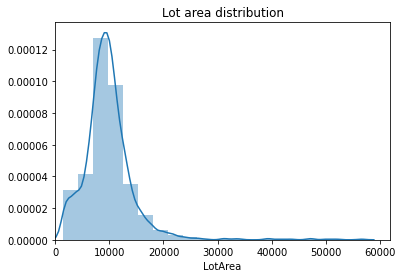

In [ ]:
ax=sns.distplot(X.LotArea, bins=20) 
ax.set_xlim(0)
ax.set_title('Lot area distribution');

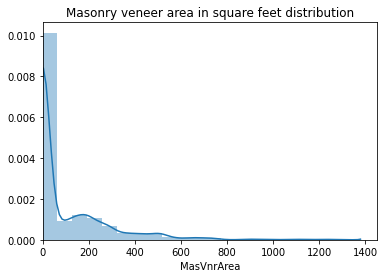

In [ ]:
ax=sns.distplot(X.MasVnrArea, bins=20) 
ax.set_xlim(0)
ax.set_title('Masonry veneer area in square feet distribution');

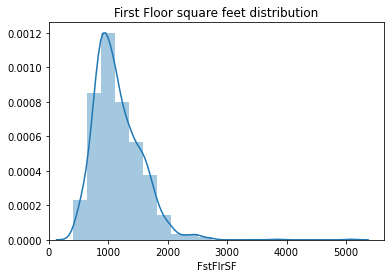

In [ ]:
ax=sns.distplot(X.FstFlrSF, bins=20) 
ax.set_xlim(0)
ax.set_title('First Floor square feet distribution');

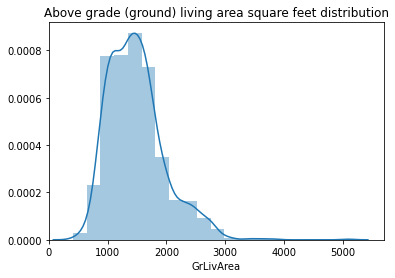

In [ ]:
ax=sns.distplot(X.GrLivArea, bins=20) 
ax.set_xlim(0)
ax.set_title('Above grade (ground) living area square feet distribution');

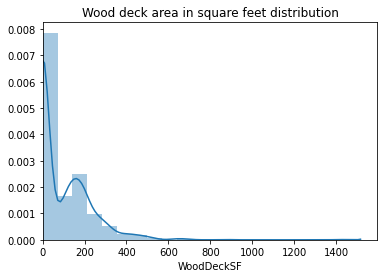

In [ ]:
ax=sns.distplot(X.WoodDeckSF, bins=20) 
ax.set_xlim(0)
ax.set_title('Wood deck area in square feet distribution');

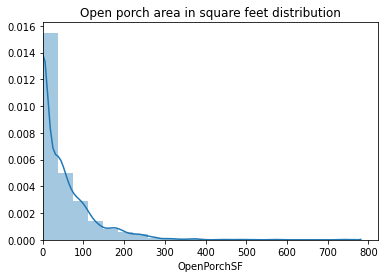

In [ ]:
ax=sns.distplot(X.OpenPorchSF, bins=20) 
ax.set_xlim(0)
ax.set_title('Open porch area in square feet distribution');

From the previous charts we determine the cut-off points from which the data will be truncated

In [ ]:
X.LotArea = np.where(X.LotArea > 30000, 30000, X.LotArea)
X.MasVnrArea = np.where(X.MasVnrArea > 600, 600, X.MasVnrArea)
X.FstFlrSF = np.where(X.FstFlrSF > 3000, 3000, X.FstFlrSF)
X.GrLivArea = np.where(X.GrLivArea > 3000, 3000, X.GrLivArea)
X.WoodDeckSF = np.where(X.WoodDeckSF > 600, 600, X.WoodDeckSF)
X.OpenPorchSF = np.where(X.OpenPorchSF > 600, 600, X.OpenPorchSF)

We analyze if there are houses that claim to have certain things (such as a garage), but their size is 0 or vice-versa. The pair of variables are:
- no basement and BsmtFinSF1
- no basement and BsmtFinSF2
- no basement and BsmtUnfSF
- Fireplaces and FireplaceQu

In [ ]:
print(pd.value_counts(X[X.BsmtFinType1=='Nb'].BsmtFinSF1))
print(pd.value_counts(X[X.BsmtFinType2=='Nb'].BsmtFinSF2))
print(pd.value_counts(X[X.BsmtFinType1=='Nb'].BsmtUnfSF))
print(pd.value_counts(X[X.Fireplaces==0].FireplaceQu))

0.0    42
Name: BsmtFinSF1, dtype: int64
0.0    42
Name: BsmtFinSF2, dtype: int64
0.0    42
Name: BsmtUnfSF, dtype: int64
0    730
Name: FireplaceQu, dtype: int64


In [ ]:
print(pd.value_counts(X[X.BsmtFinSF1==0].BsmtFinType1))
print(pd.value_counts(X[X.BsmtFinSF2==0].BsmtFinType2))
print(pd.value_counts(X[X.BsmtUnfSF==0].BsmtFinType1))
print(pd.value_counts(X[X.FireplaceQu==0].Fireplaces))

Unf    421
Nb      42
Name: BsmtFinType1, dtype: int64
Unf    1236
Nb       42
LQ        1
Name: BsmtFinType2, dtype: int64
Nb     42
GLQ    24
ALQ    17
LwQ    16
Rec    13
BLQ    12
Name: BsmtFinType1, dtype: int64
0    730
Name: Fireplaces, dtype: int64


In [ ]:
X.loc[(X.BsmtFinSF2==0)&(X.BsmtFinType2=='LQ'),'BsmtFinType2']='Unf'

# **2. Descriptive analysis**
### **2.1 Sales distribution**

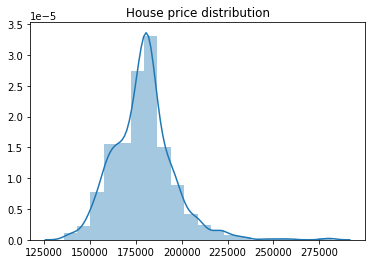

In [ ]:
ax=sns.distplot(y, bins=20) 
ax.set_title('House price distribution');

Fortunatelly the response variable distribution is quite similar to a normal distribution, this is important because if we want to use a multiple lineal regression we must assure that the errors have normal distribution.

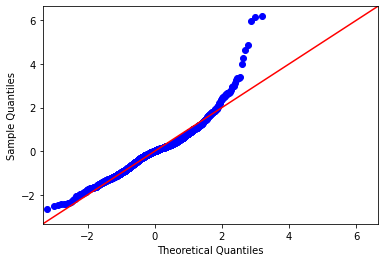

In [ ]:
data_points = ((y-y.mean())/np.sqrt(y.var())).SalePrice.values
  
sm.qqplot(data_points, line ='45') 
py.show() 

However, looking at the chart, we can observe that Sale Price has a slight asymmetry to the right and 7 point above the expected, it's advisable to remove this point if it appear in the train set.

### **2.2 Correlation Analysis - between the independent variables**
Measuring the linear correlation is important, although is not conclusive about the non-relationship between the variables since it only measures linear relationship (i.e. non-quadratic relationship is not measured)

In [ ]:
correlation=X.corr()
high_correlation=pd.DataFrame(columns=['Row','Column','Calue'])
# outlier detections:
for col in correlation.columns:
  marginal=correlation.loc[col]
  if len(marginal[(marginal>0.8)|(marginal<-0.8)])==1:
      pass
  else:
      print(col)
      print(marginal[((marginal>0.8)|(marginal<-0.8))&(marginal<1)])

Fireplaces
FireplaceQu    0.860074
Name: Fireplaces, dtype: float64
FireplaceQu
Fireplaces    0.860074
Name: FireplaceQu, dtype: float64
GarageCars
GarageArea    0.897022
Name: GarageCars, dtype: float64
GarageArea
GarageCars    0.897022
Name: GarageArea, dtype: float64
GarageQual
GarageCond    0.933789
Name: GarageQual, dtype: float64
GarageCond
GarageQual    0.933789
Name: GarageCond, dtype: float64


Primary correlation conclusions:
- As could be supposed GarageCars (Size of garage in car capacity) and GarageArea (Size of garage in square feet) are highly correlated, Garage cars was deleted.
- Fireplaces (Number of fireplaces) and FireplaceQu (Fireplace quality) are highly correlated, Fireplaces was deleted because is more important the quality than the quantity (i.e. the Fireplaces could be in poor conditions) also the majority of the houses has one or zero fireplaces
- As could be supposed too, GarageQual (Garage quality), GarageCond  (Garage condition) y hasgarage (dummy) are highly correlated. Due to GarageQual has more deviation, GarageCond and hasgarage were deleted.

In [ ]:
round(pd.crosstab(X.FireplaceQu, 
            X.Fireplaces, normalize =False,
            margins = False),2)

Fireplaces,0,1,2,3,4
FireplaceQu,,,,,
0,730,0,0,0,0
1,0,26,0,0,0
2,0,35,6,0,0
3,0,236,39,3,1
4,0,303,58,3,0
5,0,18,1,0,0


In [ ]:
round(pd.crosstab(X.GarageQual, 
            X.GarageCond, normalize =False,
            margins = False),2)

GarageCond,0,1,2,3,4,5
GarageQual,,,,,,
0,78,0,0,0,0,0
1,0,1,1,0,0,0
2,0,4,19,53,0,0
3,0,2,19,1268,4,0
4,0,0,0,7,2,1


In [ ]:
X.drop(columns=['GarageCond','GarageCars','Fireplaces'], inplace=True)

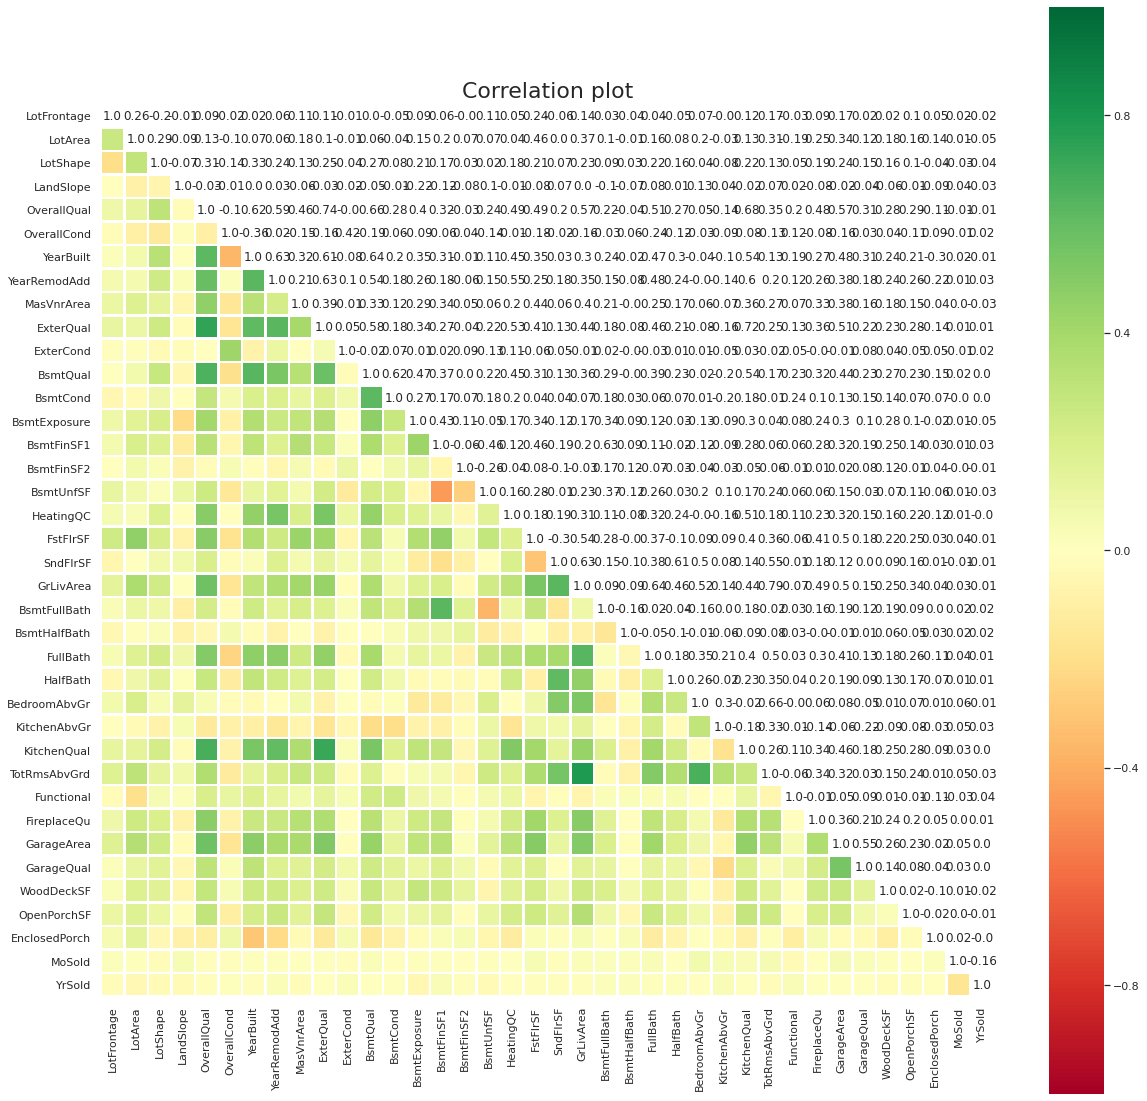

In [ ]:
sns.set(style="white")
fig, ax = plt.subplots(1, figsize=(20, 20))
corr = X.corr()
labels = corr.where(np.triu(np.ones(corr.shape)).astype(np.bool))
labels = labels.round(2)
labels = labels.replace(np.nan, ' ', regex=True)

mask = np.triu(np.ones(corr.shape)).astype(np.bool)
ax = sns.heatmap(
    corr,
    mask=mask,
    vmin=-1,
    vmax=1,
    center=0,
    cmap='RdYlGn',
    fmt='',
    square=True,
    linewidths=1.5).set_title("Correlation plot", fontsize=22)
mask = np.ones(corr.shape) - mask
ax = sns.heatmap(
    corr,
    mask=mask,
    vmin=-1,
    vmax=1,
    center=0,
    cmap=ListedColormap(['white']),
    annot=labels,
    cbar=False,
    fmt='',
    linewidths=1.5)

it can be evidenced some variables well correlated with the rest:
- OverallQual has high positive correlation with year built/ Yearremodadd, KitchenQual, ExterQual, BsmtQual it means that if a person want to improve a house overall quality is advisable to made a remodelation especially in order to improve the kitchen, the basement or the external aspect. also houses with good overall quality should have good kitchen quality, external quality or basement quality (the same happens with the other factors)
- Basement condition are well correlated with basement quality
- garage quality are well correlated with garage area.

## **2.3 Correlation with the sale price** - Numerical variables


In [ ]:
Xy=pd.merge(X, y,  how='inner',left_index=True,right_index=True)
corry=Xy.corr().SalePrice

corrColors= corry[(corry!=1)].sort_values(ascending=False).values
corrColors=np.where((corrColors>=0.7),1,corrColors)
corrColors=np.where((corrColors>=0.4)&(corrColors<0.7),2,corrColors)
corrColors=np.where((corrColors>=0.2)&(corrColors<0.4),3,corrColors)
corrColors=np.where(corrColors<0.2,4,corrColors)

mapping={1:'High',2:'Moderate',3:'Low',4:'Very Low'}

colors=[]
for i in list(corrColors):
  #print(mapping[i])
  colors.append(mapping[i])

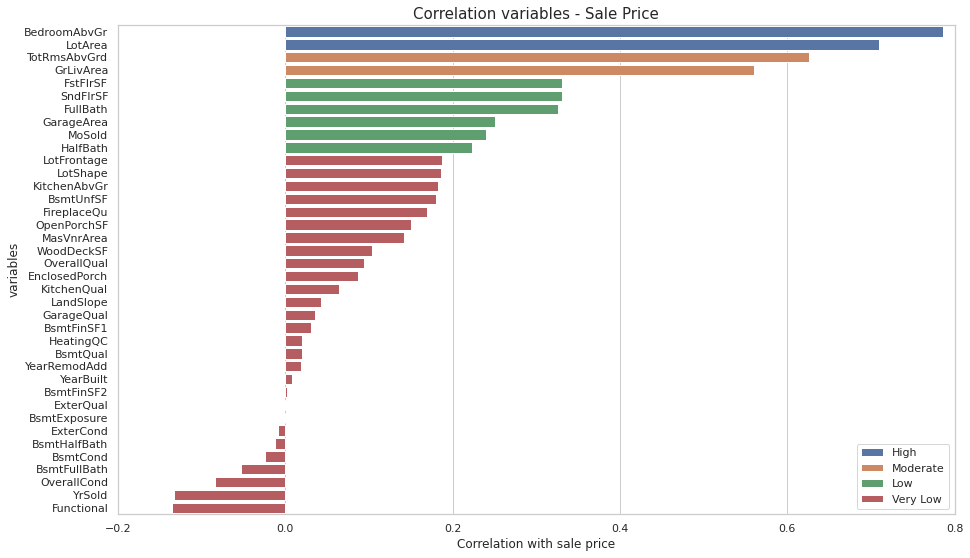

In [ ]:
sns.set(style="whitegrid")
fig = plt.figure(figsize=(15,9))
ax = sns.barplot(y=list(corry[(corry!=1)].sort_values(ascending=False).index),
                 x=list(corry[(corry!=1)].sort_values(ascending=False).values),orient='h'
                 ,hue=colors, dodge=False)
ax.set_xlim(-0.2,0.8)
ax.set_title('Correlation variables - Sale Price',fontsize=15)  
plt.legend(loc='lower right')
ax.set(ylabel="variables", xlabel='Correlation with sale price');

The sale price is highly correlated with the Number of bedrooms above basement level and Lot size, this factors are not highly correlated between then. For these reasons, it is expectable that this variables plays a crucial role in the final model. Also if somebody wants to increase a house price needs to increase the number of bedrooms or buy more land.

The sale price is moderate correlated with GrLivArea (Above grade living area square feet) and TotRmsAbvGrd (Total rooms above grade without include bathrooms), as we can see in the correlation matrix, these two variables are highly correlated. Probably one of these plays an important role in the regression, but probably one of them doesn't make an impact in the model.

Variables with very low correlations need to be analyses in order to determine if are going to be deleted or not (variables with no correlation at all with the sale price)

A negative correlation between Home functionality and the Sale price no make sense. The same situation happen between OverallCond (Rates the overall condition of the house) and Sale Price. For this reason, Functional and OverallCond variables were deleted.

In [ ]:
X.drop(columns=['Functional','OverallCond'],inplace=True)

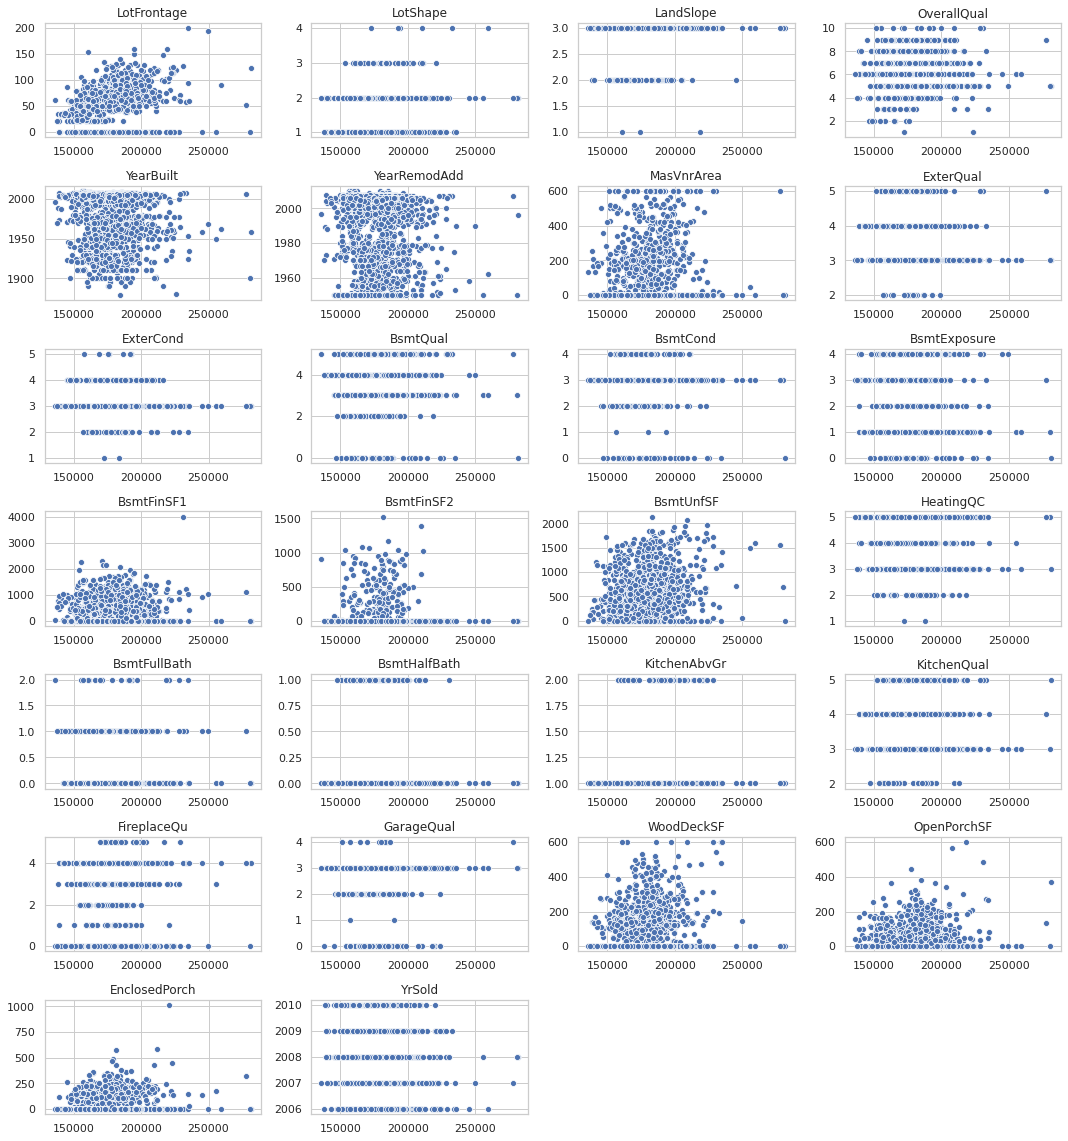

In [ ]:
Xy=pd.merge(X, y,  how='inner',left_index=True,right_index=True)
corry=Xy.corr().SalePrice
low_corr=list(corry[corry<0.2].index)
fig = plt.figure(figsize=(15,18))
for i in low_corr:
    fig.add_subplot(8,4,1+low_corr.index(i));
    sns.scatterplot(Xy['SalePrice'],Xy[i]);
    plt.xlabel('');
    plt.ylabel('');
    plt.title(i);

plt.tight_layout();
#plt.show();

For some variables the relationship with the target variable is very low, this variables were deleted: 
- YearBuilt, YearRemodAdd, MasVnrArea, BsmtQual, BsmtExposure, BsmtFinSf1, BsmtFinSf2, BsmtUnfSf, BsmtHalfBath, WoodDeckSf, OpenPorchSF, YrSold.

However, in others the variables the correlation seems to make some sense, specially can decrease in those cases when 0 is imputated when something is not present (i.e basement). The variables are:
- LotFrontage, LotShape, LandSlope, OverallQual, ExterQual, ExterCond, BsmtCond, HeatingQC, BsmtFullBath, KitchenAbvGr, KitchenQual, FireplaceQu, GarageQual, GarageCond.

In [ ]:
X.drop(columns=['YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtQual', 'BsmtExposure', 
                'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'BsmtHalfBath', 'WoodDeckSF', 'OpenPorchSF', 'YrSold'],inplace=True)

## **2.4 Relations with the sale price - Categorical variables**

In [ ]:
descriptive_table = X.describe(include='all').round(decimals=3)
description_object=descriptive_table.loc[['count','unique','top','freq']] 
description_object.dropna(axis=1, thresh=None, inplace=True)
description_object

,MSZoning,Alley,LandContour,LotConfig,Neighborhood,Condition1,BldgType,HouseStyle,RoofStyle,Exterior1st,...,BsmtFinType2,CentralAir,Electrical,GarageType,GarageFinish,PavedDrive,Fence,MiscFeature,SaleType,SaleCondition
count,1459,1459,1459,1459,1459,1459,1459,1459,1459,1459,...,1459,1459,1459,1459,1459,1459,1459,1459,1459,1459
unique,4,3,4,4,17,5,5,5,3,8,...,5,2,2,5,4,3,4,2,4,4
top,RL,No,Lvl,Inside,NAmes,Norm,1Fam,1Story,Gable,VinylSd,...,Unf,Y,SBrkr,Attchd,Unf,Y,No,No,Warranty,Normal
freq,1114,1352,1311,1081,218,1251,1205,750,1169,510,...,1238,1358,1337,853,625,1301,1169,1413,1271,1204


In [ ]:
print('Sale Price in dollars:')
round(Xy.groupby(['MSZoning'])['SalePrice'].agg(['mean','count']),0).sort_values(by='mean' ,ascending=False)

Sale Price in dollars:


,mean,count
MSZoning,,
RL,181911.0,1114
Other,177579.0,29
RM,170408.0,242
FV,167461.0,74


Floating Village Residential and Residential Medium Density has lower prices than Residential Low Density houses.


In [ ]:
print('Sale Price in dollars:')
price=round(Xy.groupby(['Alley'])['SalePrice'].agg(['mean','count']),0).sort_values(by='mean' ,ascending=False)

Sale Price in dollars:


Houses with a pave alley cost in average 13.000 USD less than the No Alley or Gravel Houses

In [ ]:
print('Sale Price in dollars:')
round(Xy.groupby(['LandContour'])['SalePrice'].agg(['mean','count']),0).sort_values(by='mean' ,ascending=False)

Sale Price in dollars:


,mean,count
LandContour,,
Low,187350.0,24
Bnk,181791.0,54
Lvl,179043.0,1311
HLS,177008.0,70


Properties in a depression land contour has more value than other types of land contour, however there are only 24 houses, thus this value is not so confident.

In [ ]:
print('Sale Price in dollars:')
round(Xy.groupby(['LotConfig'])['SalePrice'].agg(['mean','count']),0).sort_values(by='mean' ,ascending=False)

Sale Price in dollars:


,mean,count
LotConfig,,
CulDSac,187930.0,82
Corner,180226.0,248
FR23,180150.0,48
Inside,178239.0,1081


Properties with a Cul-de-sac lot config has an increase in their value of approximate 8.000 USD.

Neighbourhood was divided in socioeconomical level acoording to houses prices determining 4 segments:
- Rich neighbourhood
- Medium-rich neighbourhood
- Medium-poor neighbourhood
- Poor neighbourhood

In [ ]:
neighbuourhood=round(Xy.groupby(['Neighborhood'])['SalePrice'].mean(),0).sort_values(ascending=False)

In [ ]:
colors_map= np.array(list(neighbuourhood.values))
colors_map=np.where(colors_map>=185000,1,colors_map)
colors_map=np.where(colors_map>=180000,2,colors_map)
colors_map=np.where(colors_map>=175000,3,colors_map)
colors_map=np.where(colors_map>=16500,4,colors_map)

mapping={1:'Rich',2:'Medium_Rich',3:'Medium_Poor',4:'Poor'}

colors=[]
for i in list(colors_map):
  #print(mapping[i])
  colors.append(mapping[i])

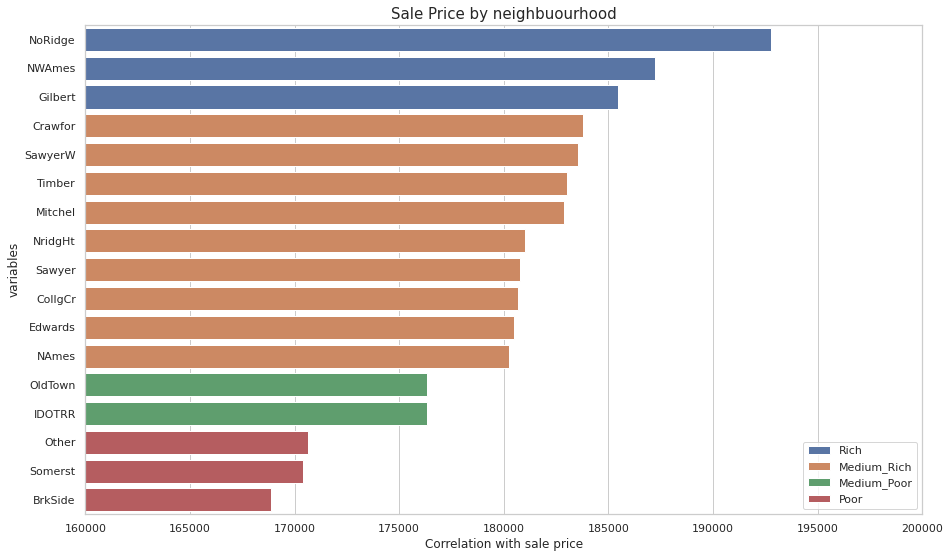

In [ ]:
sns.set(style="whitegrid")
fig = plt.figure(figsize=(15,9))
ax = sns.barplot(y=list(neighbuourhood.index),
                 x=list(neighbuourhood.values),orient='h'
                 , dodge=False,hue=colors) 

ax.set_xlim(160000,200000)
ax.set_title('Sale Price by neighbuourhood',fontsize=15)  
plt.legend(loc='lower right')
ax.set(ylabel="variables", xlabel='Correlation with sale price');

In [ ]:
mapping={'NoRidge':'Rich', 'NWAmes':'Rich', 'Gilbert':'Rich',
         'Crawfor':'Medium_Rich', 'SawyerW':'Medium_Rich',
         'Timber':'Medium_Rich', 'Mitchel':'Medium_Rich',
         'NridgHt':'Medium_Rich', 'Sawyer':'Medium_Rich',
         'CollgCr':'Medium_Rich','Edwards':'Medium_Rich','NAmes':'Medium_Rich',
         'OldTown':'Medium_Poor','IDOTRR':'Medium_Poor',
         'Other':'Poor','Somerst':'Poor','BrkSide':'Poor'}

X['socioconomical_level']= X.Neighborhood.map(mapping)

In [ ]:
print('Sale Price in dollars:')
round(Xy.groupby(['Condition1'])['SalePrice'].agg(['mean','count']),0).sort_values(by='mean' ,ascending=False)

Sale Price in dollars:


,mean,count
Condition1,,
Pos,188281.0,32
RRN,183024.0,49
Feedr,181305.0,83
Artery,180984.0,44
Norm,178597.0,1251


Properties near something positive have more value than the others, also, houses closes to the Railroad have more value than normal houses.

In [ ]:
print('Sale Price in dollars:')
round(Xy.groupby(['BldgType'])['SalePrice'].agg(['mean','count']),0).sort_values(by='mean' ,ascending=False)

Sale Price in dollars:


,mean,count
BldgType,,
Duplex,193805.0,57
2fmCon,184665.0,31
1Fam,181252.0,1205
Twnhs,158204.0,53
TwnhsE,158097.0,113


Duplex were better sold than other houses. on the other hand Townhouse were worse sold than other type of houses.

In [ ]:
print('Sale Price in dollars:')
round(Xy.groupby(['HouseStyle'])['SalePrice'].agg(['mean','count']),0).sort_values(by='mean' ,ascending=False)

Sale Price in dollars:


,mean,count
HouseStyle,,
2Story,184583.0,440
SLvl,181484.0,63
1.5Fin,179307.0,160
1Story,176418.0,750
SFoyer,169055.0,46


Properties with two stories or more have more value than others. On the other side Split Foyer houses have less value than  others.

In [ ]:
print('Sale Price in dollars:')
round(Xy.groupby(['RoofStyle'])['SalePrice'].agg(['mean','count']),0).sort_values(by='mean' ,ascending=False)

Sale Price in dollars:


,mean,count
RoofStyle,,
Hip,182878.0,265
Other,181411.0,25
Gable,178299.0,1169


Hip Roofstyle have more value than Gable

In [ ]:
print('Sale Price in dollars:')
round(Xy.groupby(['Exterior1st'])['SalePrice'].agg(['mean','count']),0).sort_values(by='mean' ,ascending=False)

Sale Price in dollars:


,mean,count
Exterior1st,,
Brick,184922.0,41
Plywood,183028.0,113
HdBoard,180746.0,220
VinylSd,180435.0,510
Wood,179441.0,235
Other,174890.0,45
MetalSd,174584.0,230
CemntBd,172096.0,65


Exterior covering on house with Brick and Plywood have more value than the others. in the other hand, Exterior covering on house with Cement Board or Metal Siding have less value than others.

In [ ]:
print('Sale Price in dollars:')
round(Xy.groupby(['MasVnrType'])['SalePrice'].agg(['mean','count']),0).sort_values(by='mean' ,ascending=False)

Sale Price in dollars:


,mean,count
MasVnrType,,
Brick,182038.0,444
Stone,178447.0,121
None,177866.0,894


Properties with brick masonry veneer type have more value than other houses.

In [ ]:
print('Sale Price in dollars:')
round(Xy.groupby(['CentralAir'])['SalePrice'].agg(['mean','count']),0).sort_values(by='mean' ,ascending=False)

Sale Price in dollars:


,mean,count
CentralAir,,
Y,179506.0,1358
N,174849.0,101


Houses with Central air conditioning have more value than those which don't have it.

In [ ]:
print('Sale Price in dollars:')
round(Xy.groupby(['Electrical'])['SalePrice'].agg(['mean','count']),0).sort_values(by='mean' ,ascending=False)

Sale Price in dollars:


,mean,count
Electrical,,
SBrkr,179448.0,1337
Fuse,176286.0,122


Houses with fuse electrical system have less value

In [ ]:
print('Sale Price in dollars:')
round(Xy.groupby(['GarageType'])['SalePrice'].agg(['mean','count']),0).sort_values(by='mean' ,ascending=False)

Sale Price in dollars:


,mean,count
GarageType,,
BuiltIn,189212.0,98
Other,182824.0,40
Attchd,179679.0,853
No,177893.0,76
Detchd,175478.0,392


Houses with Built-In garage (Garage part of house - typically has room above garage) have more value than others. On the other hand, houses with garage detached from home have less value

In [ ]:
print('Sale Price in dollars:')
round(Xy.groupby(['PavedDrive'])['SalePrice'].agg(['mean','count']),0).sort_values(by='mean' ,ascending=False)

Sale Price in dollars:


,mean,count
PavedDrive,,
Y,179476.0,1301
P,179251.0,32
N,176147.0,126


Properties without paved driveway have less value.

In [ ]:
print('Sale Price in dollars:')
round(Xy.groupby(['MiscFeature'])['SalePrice'].agg(['mean','count']),0).sort_values(by='mean' ,ascending=False)

Sale Price in dollars:


,mean,count
MiscFeature,,
Shed,185340.0,46
No,178984.0,1413


Houses with Shed have more value than the others

In [ ]:
print('Sale Price in dollars:')
round(Xy.groupby(['SaleType'])['SalePrice'].agg(['mean','count']),0).sort_values(by='mean' ,ascending=False)

Sale Price in dollars:


,mean,count
SaleType,,
New,181332.0,117
Warranty,179143.0,1271
COD,177989.0,44
Contract,173727.0,27


New houses were sold at a higher value. On the hand, houses sold by contract were sold at a lower value.

# **3. Regression Analysis**
## 3.1 Basic preprocessing 
Train, test, scaler, etc.

The data was divided into two mutually exclusive subsets:

- Train: This subset is use to train the model.
- Test: This subset is use to verify that the model reproduce the desired results.

In [ ]:
X.describe()

,LotFrontage,LotArea,LotShape,LandSlope,OverallQual,ExterQual,ExterCond,BsmtCond,HeatingQC,FstFlrSF,...,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,FireplaceQu,GarageArea,GarageQual,EnclosedPorch,MoSold
count,1459.000000,1459.000000,1459.000000,1459.000000,1459.000000,1459.000000,1459.000000,1459.000000,1459.000000,1459.000000,...,1459.000000,1459.000000,1459.000000,1459.000000,1459.000000,1459.000000,1459.000000,1459.000000,1459.000000,1459.000000
mean,57.910212,9712.026045,1.392049,2.954764,6.078821,3.397533,3.087731,2.901988,4.158328,1154.536669,...,0.377656,2.854010,1.043866,3.509938,6.385195,1.710761,472.444825,2.791638,43.102125,6.104181
std,32.266054,4285.465336,0.557864,0.217566,1.436812,0.586444,0.392637,0.596621,0.956684,384.303536,...,0.503017,0.829788,0.204866,0.660780,1.508895,1.801147,217.326902,0.708879,87.330749,2.722432
min,0.000000,1470.000000,1.000000,1.000000,1.000000,2.000000,1.000000,0.000000,1.000000,407.000000,...,0.000000,0.000000,1.000000,2.000000,3.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,44.000000,7391.000000,1.000000,3.000000,5.000000,3.000000,3.000000,3.000000,3.000000,873.500000,...,0.000000,2.000000,1.000000,3.000000,5.000000,0.000000,317.500000,3.000000,0.000000,4.000000
50%,63.000000,9399.000000,1.000000,3.000000,6.000000,3.000000,3.000000,3.000000,5.000000,1079.000000,...,0.000000,3.000000,1.000000,3.000000,6.000000,0.000000,480.000000,3.000000,0.000000,6.000000
75%,78.000000,11517.500000,2.000000,3.000000,7.000000,4.000000,3.000000,3.000000,5.000000,1382.500000,...,1.000000,3.000000,1.000000,4.000000,7.000000,4.000000,576.000000,3.000000,40.500000,8.000000
max,200.000000,30000.000000,4.000000,3.000000,10.000000,5.000000,5.000000,4.000000,5.000000,3000.000000,...,2.000000,6.000000,2.000000,5.000000,15.000000,5.000000,1488.000000,4.000000,1012.000000,12.000000


In [ ]:
X_dummies= pd.get_dummies(X,drop_first=True )

In [ ]:
# get train and test data
Xtrain, Xtest, ytrain, ytest = train_test_split(X_dummies, y, random_state=0,test_size =0.2)

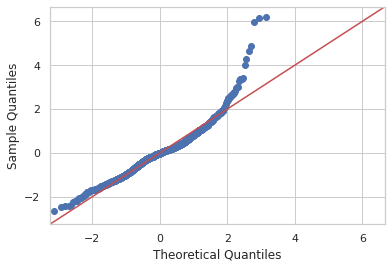

In [ ]:
data_points = ((ytrain-ytrain.mean())/np.sqrt(ytrain.var())).SalePrice.values
  
sm.qqplot(data_points, line ='45') 
py.show() 

Delete Atypical data points (houses with Sale Price above 245,000 USD)

In [ ]:
ytrain.sort_values(by='SalePrice',ascending=False).head(10)

,SalePrice
Id,
2189,281643.976117
2251,280618.132617
2264,277936.126944
2797,259423.859148
1948,255629.490470
2265,249768.279823
2901,245283.198338
2823,235419.373449
2600,234707.209860


In [ ]:
non_atypical_index=set(list(ytrain.index)) - set(list(ytrain.sort_values(by='SalePrice',ascending=False).head(7).index))

ytrain=ytrain[ytrain.index.isin(non_atypical_index)]
Xtrain=Xtrain[Xtrain.index.isin(non_atypical_index)]

In [ ]:
Xtrain

,LotFrontage,LotArea,LotShape,LandSlope,OverallQual,ExterQual,ExterCond,BsmtCond,HeatingQC,FstFlrSF,...,MiscFeature_Shed,SaleType_Contract,SaleType_New,SaleType_Warranty,SaleCondition_Normal,SaleCondition_Other,SaleCondition_Partial,socioconomical_level_Medium_Rich,socioconomical_level_Poor,socioconomical_level_Rich
Id,,,,,,,,,,,,,,,,,,,,,
1553,60.0,12900,1,3,6,4,4,3,5,780,...,0,0,0,1,1,0,0,0,0,0
2299,99.0,13069,2,3,8,4,3,3,5,1718,...,0,0,0,1,1,0,0,1,0,0
1821,60.0,5400,1,3,6,2,3,3,5,1044,...,0,1,0,0,0,1,0,0,0,0
2126,60.0,9144,1,3,6,3,4,3,5,1170,...,0,0,0,1,1,0,0,0,1,0
1501,0.0,2980,1,3,6,4,3,3,5,756,...,0,0,0,1,1,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2224,0.0,11050,1,3,7,3,3,3,5,910,...,0,0,0,1,1,0,0,1,0,0
2296,134.0,16659,2,3,8,4,3,3,5,1582,...,0,0,1,0,0,0,1,1,0,0
2677,0.0,8658,2,3,6,3,3,3,5,1008,...,0,0,0,1,1,0,0,0,0,1


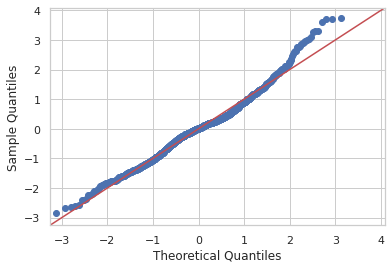

In [ ]:
data_points = ((ytrain-ytrain.mean())/np.sqrt(ytrain.var())).SalePrice.values
  
sm.qqplot(data_points, line ='45') 
py.show() 

Sales prices distribution improves a lot and now is much more similar than a normal distribution than before

In [ ]:
#data standarization
scaler = StandardScaler()
Xtrain=scaler.fit_transform(Xtrain)
Xtest=scaler.transform(Xtest)

In [ ]:
## 3.2 Baseline
A fundamental aspect of the models is to compare them with a baseline. In this case we will take as a baseline the error derived from estimating all the scores as the average score of the training data.

In [ ]:
base=ytrain.mean()
print('Base:',round(base[0],2))
print('Mean Absolute Error:', round(metrics.mean_absolute_error(ytest, [base] * len(ytest)),2))  
print('Mean Squared Error:', round(metrics.mean_squared_error(ytest, [base] * len(ytest)),2))  
print('Root Mean Squared Error:', round(np.sqrt(metrics.mean_squared_error(ytest, [base] * len(ytest))),2))

Base: 178777.25
Mean Absolute Error: 12817.26
Mean Squared Error: 280169188.19
Root Mean Squared Error: 16738.26


In [ ]:
## 3.3 Linear Regression Techniques
1. **Simple Linear Regression**: The objective function (also called as the cost) to be minimized is just the RSS (Residual Sum of Squares), i.e. the sum of squared errors of the predicted outcome as compared to the actual outcome.
2. **Ridge Regression**: The objective function to be minimized is the RSS plus the sum of square of the magnitude of weights.
3. **Lasso Regression**: The objective function to be minimized is the RSS plus the sum of absolute value of the magnitude of weights.

Ridge and lasso penalized the indiscriminated used of variables and this is very important to avoid overfitting (good training result, poor testing result), for this reason lasso and ridge regression are going to be used

### 3.3.1 Ridge Regression

In [ ]:
alpha_grid=list(range(1, 500, 1))
alpha_grid = [x / 100 for x in alpha_grid]

ridge_params = {'alpha':alpha_grid,'fit_intercept':[True,False]}

reg_ridge_best_model =GridSearchCV(linear_model.Ridge(normalize=False), param_grid=ridge_params , 
                                   scoring='neg_mean_absolute_error',
                                   n_jobs=12,cv=5, verbose=2)

reg_ridge_best_model.fit(Xtrain, ytrain)

ypred = reg_ridge_best_model.predict(Xtest)

print('Result in test set:')
print('Mean Absolute Error:', metrics.mean_absolute_error(ytest, ypred))  
print('Mean Squared Error:', metrics.mean_squared_error(ytest, ypred))  
print('Root Mean Squared Error:', np.sqrt(metrics.mean_squared_error(ytest, ypred)))

Fitting 5 folds for each of 998 candidates, totalling 4990 fits


[Parallel(n_jobs=12)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  17 tasks      | elapsed:    2.6s
[Parallel(n_jobs=12)]: Done 138 tasks      | elapsed:    7.8s
[Parallel(n_jobs=12)]: Done 341 tasks      | elapsed:   16.4s
[Parallel(n_jobs=12)]: Done 624 tasks      | elapsed:   26.2s
[Parallel(n_jobs=12)]: Done 989 tasks      | elapsed:   43.0s
[Parallel(n_jobs=12)]: Done 1434 tasks      | elapsed:   59.6s
[Parallel(n_jobs=12)]: Done 1961 tasks      | elapsed:  1.3min
[Parallel(n_jobs=12)]: Done 2568 tasks      | elapsed:  1.7min
[Parallel(n_jobs=12)]: Done 3257 tasks      | elapsed:  2.1min
[Parallel(n_jobs=12)]: Done 4026 tasks      | elapsed:  2.6min
[Parallel(n_jobs=12)]: Done 4877 tasks      | elapsed:  3.1min


Result in test set:
Mean Absolute Error: 1215.0467304335173
Mean Squared Error: 4144122.327196768
Root Mean Squared Error: 2035.711749535471


[Parallel(n_jobs=12)]: Done 4990 out of 4990 | elapsed:  3.2min finished


In [ ]:
print('Result in training set:')
ypred_train = reg_ridge_best_model.predict(Xtrain)
print('Mean Absolute Error:', metrics.mean_absolute_error(ytrain, ypred_train))  
print('Mean Squared Error:', metrics.mean_squared_error(ytrain, ypred_train))  
print('Root Mean Squared Error:', np.sqrt(metrics.mean_squared_error(ytrain, ypred_train)))

Result in training set:
Mean Absolute Error: 958.7166173250705
Mean Squared Error: 1642253.705779159
Root Mean Squared Error: 1281.504469668038


In [ ]:
reg_ridge_best_model.best_params_

{'alpha': 2.01, 'fit_intercept': True}

In [ ]:
with open(os.path.join('Models', 'reg_ridge_best_model.pkl'), 'wb') as f:
        pickle.dump(reg_ridge_best_model, f)

### 3.3.2 Lasso Regression

In [ ]:
lasso_params = {'alpha':list(np.linspace(0, 100, 200))
               ,'fit_intercept':[True,False]}

reg_lasso_best_model =GridSearchCV(linear_model.Lasso(normalize=False), param_grid=lasso_params,
                                   scoring='neg_mean_absolute_error',
                                   n_jobs=12,cv=3, verbose=2)
reg_lasso_best_model.fit(Xtrain, ytrain)

ypred = reg_lasso_best_model.predict(Xtest)

print('Result in test set:')
print('Mean Absolute Error:', metrics.mean_absolute_error(ytest, ypred))  
print('Mean Squared Error:', metrics.mean_squared_error(ytest, ypred))  
print('Root Mean Squared Error:', np.sqrt(metrics.mean_squared_error(ytest, ypred)))

Fitting 3 folds for each of 400 candidates, totalling 1200 fits


[Parallel(n_jobs=12)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  17 tasks      | elapsed:   10.8s
[Parallel(n_jobs=12)]: Done 138 tasks      | elapsed:   30.8s
[Parallel(n_jobs=12)]: Done 341 tasks      | elapsed:   51.0s
[Parallel(n_jobs=12)]: Done 624 tasks      | elapsed:  1.5min
[Parallel(n_jobs=12)]: Done 989 tasks      | elapsed:  2.2min


Result in test set:
Mean Absolute Error: 1161.297324532842
Mean Squared Error: 3884649.2908687633
Root Mean Squared Error: 1970.9513669466235


[Parallel(n_jobs=12)]: Done 1200 out of 1200 | elapsed:  2.5min finished


In [ ]:
print('Result in training set:')
ypred_train = reg_lasso_best_model.predict(Xtrain)
print('Mean Absolute Error:', metrics.mean_absolute_error(ytrain, ypred_train))  
print('Mean Squared Error:', metrics.mean_squared_error(ytrain, ypred_train))  
print('Root Mean Squared Error:', np.sqrt(metrics.mean_squared_error(ytrain, ypred_train)))

Result in training set:
Mean Absolute Error: 986.9750877070229
Mean Squared Error: 1845482.185041133
Root Mean Squared Error: 1358.4852538916766


As it could be seeing, Lasso Regression returns betters results in the test set and the difference between result in training and test set are less (less difference between results in training and test set derive in less overfitting). For these reasons, the Lasso regression was selected as the model for adjust data.

Another aspect is that for variables with small coefficients, it means that the algorithm is able to predict the outcome fairly well even without the variable, lasso is prone to removed from the equation by setting a zero coefficient. 

In [ ]:
print('Coefficient between training and test set results:')
ypred_train = reg_lasso_best_model.predict(Xtrain)
print('Mean Absolute Error:',  
      round(metrics.mean_absolute_error(ytest, ypred)/metrics.mean_absolute_error(ytrain, ypred_train),2))    
print('Root Mean Squared Error:', 
      round(np.sqrt(metrics.mean_squared_error(ytest, ypred))/np.sqrt(metrics.mean_squared_error(ytrain, ypred_train)),2))

Coefficient between training and test set results:
Mean Absolute Error: 1.18
Root Mean Squared Error: 1.45


Consider the MAE coefficient (Mean Absolute error), the results gets worse in 18%. On the other side, if Root Mean Square Error is consider, the results get worse in 45%, however is prone to being influenced by outliers.

In [ ]:
reg_lasso_best_model.best_params_

{'alpha': 58.291457286432156, 'fit_intercept': True}

In [ ]:
with open(os.path.join('Models', 'reg_lasso_best_model.pkl'), 'wb') as f:
        pickle.dump(reg_lasso_best_model, f)

In [ ]:
reg_lasso = linear_model.Lasso(normalize=False, alpha = 58.29, fit_intercept= True)
reg_lasso.fit(Xtrain, ytrain)
ypred = reg_lasso.predict(Xtest)

In [ ]:
reg_lasso.coef_[reg_lasso.coef_!=0]

array([ 2.60048111e+01,  7.97478030e+03, -2.46962055e+01, -1.10834998e+01,
       -2.71704131e+01,  1.06256107e+04,  9.12511251e+01, -1.68662922e+01,
        3.07115401e+03,  2.76930982e-01,  1.38530403e+01,  5.13250534e+00,
       -3.41731391e+00, -1.17432259e+01,  1.71776703e+01, -1.83846509e+01,
        5.88079312e+01,  1.28863019e+01,  8.18220854e+01,  3.22930384e+01,
       -6.45085912e+01,  1.31069956e+02])

In [ ]:
reg_lasso.coef_

array([ 2.60048111e+01,  7.97478030e+03, -0.00000000e+00,  0.00000000e+00,
       -0.00000000e+00, -2.46962055e+01, -1.10834998e+01, -0.00000000e+00,
        0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
       -2.71704131e+01, -0.00000000e+00, -0.00000000e+00,  1.06256107e+04,
       -0.00000000e+00, -0.00000000e+00,  9.12511251e+01, -1.68662922e+01,
        0.00000000e+00, -0.00000000e+00, -0.00000000e+00,  3.07115401e+03,
       -0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
        0.00000000e+00,  0.00000000e+00, -0.00000000e+00,  0.00000000e+00,
       -0.00000000e+00, -0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
       -0.00000000e+00,  0.00000000e+00, -0.00000000e+00,  2.76930982e-01,
        1.38530403e+01,  0.00000000e+00, -0.00000000e+00,  0.00000000e+00,
       -0.00000000e+00, -0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
       -0.00000000e+00, -0.00000000e+00, -0.00000000e+00, -0.00000000e+00,
       -0.00000000e+00, -

In [ ]:
model_columns=pd.DataFrame(X_dummies.columns,columns=['Columns'])
model_columns['coefficients']=list(reg_lasso.coef_)
model_columns=model_columns[list(reg_lasso.coef_!=0)]

In [ ]:
model_columns

,Columns,coefficients
0,LotFrontage,26.004811
1,LotArea,7974.780298
5,ExterQual,-24.696205
6,ExterCond,-11.083500
12,BsmtFullBath,-27.170413
15,BedroomAbvGr,10625.610698
18,TotRmsAbvGrd,91.251125
19,FireplaceQu,-16.866292
23,MoSold,3071.154013
39,Neighborhood_IDOTRR,0.276931


## **3.4 Other Regression techniques**

### **3.4.1 Random forrest regressor**

In [ ]:
max_depth = list(range(3,12))
max_depth.append(None)


parameters = {
    'n_estimators': list(range(10, 501, 10)), 
    'max_leaf_nodes': list(range(6, 60, 1)), 
    'max_depth': max_depth
}


reg_rf_best_model = RandomizedSearchCV(estimator=RandomForestRegressor(),
                       param_distributions = parameters, n_iter = 500,
                       scoring='neg_mean_absolute_error',
                       n_jobs=12,cv=3, verbose=2)

reg_rf_best_model.fit(Xtrain, ytrain)

ypred = reg_rf_best_model.predict(Xtest)


print('Mean Absolute Error:', metrics.mean_absolute_error(ytest, ypred))  
print('Mean Squared Error:', metrics.mean_squared_error(ytest, ypred))  
print('Root Mean Squared Error:', np.sqrt(metrics.mean_squared_error(ytest, ypred)))

Fitting 3 folds for each of 500 candidates, totalling 1500 fits


[Parallel(n_jobs=12)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  17 tasks      | elapsed:    2.6s
[Parallel(n_jobs=12)]: Done 138 tasks      | elapsed:   19.0s
[Parallel(n_jobs=12)]: Done 341 tasks      | elapsed:   47.5s
[Parallel(n_jobs=12)]: Done 624 tasks      | elapsed:  1.4min
[Parallel(n_jobs=12)]: Done 989 tasks      | elapsed:  2.3min
[Parallel(n_jobs=12)]: Done 1434 tasks      | elapsed:  3.3min
[Parallel(n_jobs=12)]: Done 1500 out of 1500 | elapsed:  3.5min finished


Mean Absolute Error: 1823.7555361621442
Mean Squared Error: 8138599.698284128
Root Mean Squared Error: 2852.823110233813


In [ ]:
reg_rf_best_model.best_params_

{'n_estimators': 70, 'max_leaf_nodes': 58, 'max_depth': 8}

### **3.4.2 XGboost**

In [ ]:
max_depth = list(range(3,12))
max_depth.append(None)

parameters = {
    'n_estimators':  list(range(10, 501, 10)), 
    'learning_rate': [x / 100 for x in range(5, 10, 1)], 
    'max_depth': max_depth
}

reg_xg_best_model = RandomizedSearchCV(estimator=XGBRegressor(objective='reg:squarederror'),
                       param_distributions = parameters, n_iter = 500,
                       scoring='neg_mean_absolute_error',
                       n_jobs=12,cv=3, verbose=2)

reg_xg_best_model.fit(Xtrain, ytrain)

ypred = reg_xg_best_model.predict(Xtest)

print('Mean Absolute Error:', metrics.mean_absolute_error(ytest, ypred))  
print('Mean Squared Error:', metrics.mean_squared_error(ytest, ypred))  
print('Root Mean Squared Error:', np.sqrt(metrics.mean_squared_error(ytest, ypred)))

Fitting 3 folds for each of 500 candidates, totalling 1500 fits


[Parallel(n_jobs=12)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  17 tasks      | elapsed:    2.7s
[Parallel(n_jobs=12)]: Done 214 tasks      | elapsed:   31.4s
[Parallel(n_jobs=12)]: Done 417 tasks      | elapsed:   58.8s
[Parallel(n_jobs=12)]: Done 700 tasks      | elapsed:  1.6min
[Parallel(n_jobs=12)]: Done 1065 tasks      | elapsed:  2.6min
[Parallel(n_jobs=12)]: Done 1500 out of 1500 | elapsed:  3.6min finished


Mean Absolute Error: 1525.8447768492667
Mean Squared Error: 6397370.434770415
Root Mean Squared Error: 2529.3023612787806


Despite the fact that all the regression methods returns better results than the baseline, Others regression techniques return worse results than linear regression techniques.